<!-- d2l:prose id=test-models-md-1 fw=all -->

# Two Test Models

Analytical models such as the two-dimensional quadratic valley explain how curvature and gradient noise govern simple update rules, but evaluating modern optimizers requires empirical measurement on real neural networks. Why does AdamW outperform SGD by a wide margin on Transformers while offering a much smaller advantage on convolutional networks? Answering such questions requires training actual models under a controlled experimental protocol.

Because stochastic training runs vary across random initializations and minibatch draws, a difference between two optimizer configurations is meaningful only if it exceeds the run-to-run variation of a single configuration. This section defines the two benchmark architectures used throughout the rest of this chapter—the byte-level Transformer language model `TinyLM` ($470{,}784$ parameters) and the convolutional classifier `FashionCNN` ($421{,}642$ parameters)—along with our shared training loop, learning-rate sweep harness, baseline SGD measurements, and significance thresholds.

In [1]:
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

In [2]:
import os
import pandas as pd
import random
import textwrap

<!-- d2l:prose id=test-models-md-2 fw=all -->

## The Language Model TinyLM

`TinyLM` is an autoregressive byte-level language model that predicts the next UTF-8 byte ($V = 256$) given a context window of $64$ consecutive bytes (that section). A standard $2{,}000$-step run with minibatches of $64$ windows processes $2{,}000 \times 64 \times 64 \approx 8.2 \times 10^6$ target bytes. To avoid repeating training examples (which would conflate optimization speed with memorization), we train on the first shard of WikiText-103 [@Merity.Xiong.Bradbury.ea.2016] ($\sim 2.7 \times 10^8$ UTF-8 bytes of Wikipedia articles). Each training minibatch samples $64$ windows at random byte offsets, so a $2{,}000$-step run sees only $\sim 3\%$ of the corpus and every training step evaluates fresh text. Validation perplexity is measured on consecutive non-overlapping windows of the $1.1 \times 10^6$-byte validation split.

In [3]:
class WikiText103(d2l.DataModule):
    """WikiText-103 as UTF-8 bytes, cut into windows of num_steps bytes."""
    def __init__(self, batch_size, num_steps, num_train=None, num_val=None):
        super().__init__()
        self.save_hyperparameters()
        self.vocab = d2l.BPETokenizer(vocab_size=256, specials=())  # Bytes
        self.train = self._read('train-00000-of-00002',
                                '3cbc792dfc0eeedf8d7333acdc15a9f536032d9a')
        self.val = self._read('validation-00000-of-00001',
                              '49d15019b0476afc752bd5f010b5a2aab2de89ca')
        self.train, self.val = self.train[:num_train], self.val[:num_val]

    def _read(self, split, sha1):
        url = ('https://huggingface.co/datasets/Salesforce/wikitext/resolve/'
               f'main/wikitext-103-raw-v1/{split}.parquet')
        fname = d2l.download(url, os.path.join(self.root, 'wikitext-103'),
                             sha1)
        lines = pd.read_parquet(fname)['text']  # Each line ends with '\n'
        return np.frombuffer(b''.join(s.encode() for s in lines), np.uint8)

    def windows(self, corpus, starts):
        """Inputs and next-byte targets of the windows at `starts`."""
        idx = np.asarray(starts)[:, None] + np.arange(self.num_steps + 1)
        array = torch.from_numpy(corpus[idx].astype(np.int64))
        return array[:, :-1], array[:, 1:]

    def train_dataloader(self):  # A pass of minibatches at random offsets
        n = len(self.train) - self.num_steps
        for _ in range(n // (self.batch_size * self.num_steps)):
            yield self.windows(self.train,
                               torch.randint(n, (self.batch_size,)).numpy())

    def val_dataloader(self):  # Consecutive, non-overlapping windows
        starts = np.arange(0, len(self.val) - self.num_steps, self.num_steps)
        for i in range(0, len(starts), self.batch_size):
            yield self.windows(self.val, starts[i:i + self.batch_size])

<!-- d2l:prose id=test-models-md-3 fw=all -->

Instantiating `WikiText103(batch_size=64, num_steps=64)` downloads the training and validation shards and decodes the opening $300$ bytes of the corpus:

In [4]:
data = WikiText103(batch_size=64, num_steps=64)
print(f'{len(data.train):,} training bytes, '
      f'{len(data.val):,} validation bytes')
text = data.vocab.decode(data.train[:300])
print('\n'.join(textwrap.fill(line, 72) for line in text.splitlines()))

269,630,498 training bytes, 1,144,248 validation bytes
 = Valkyria Chronicles III =
 Senjō no Valkyria 3 : Unrecorded Chronicles ( Japanese : 戦場のヴァルキュリア3 ,
lit . Valkyria of the Battlefield 3 ) , commonly referred to as Valkyria
Chronicles III outside Japan , is a tactical role @-@ playing video game
developed by Sega and Media.Vis


<!-- d2l:prose id=test-models-md-4 fw=all -->

### Architecture and Parameter Groups

`TinyLM` is a two-block decoder-only Transformer (that section) with embedding width $d_{\text{model}} = 128$, $2$ causal attention heads, and a two-layer GELU MLP of hidden width $4 d_{\text{model}} = 512$ per block. Each sublayer is preceded by LayerNorm (that section) and wrapped in a residual connection, followed by a final LayerNorm and linear output head projecting to $256$ byte logits. Embedding rows are initialized from $\mathcal{N}(0, 1)$, and all linear weights and biases are drawn uniformly from $[-1/\sqrt{\text{fan-in}}, 1/\sqrt{\text{fan-in}}]$.

In [5]:
class TinyLM(nn.Module):
    """A small decoder-only transformer language model."""
    def __init__(self, vocab_size, d_model=128, num_heads=2, num_blks=2,
                 max_len=64):
        super().__init__()
        self.num_heads = num_heads
        self.token_emb = nn.Embedding(vocab_size, d_model)
        self.pos_emb = nn.Embedding(max_len, d_model)
        self.blks = nn.ModuleList([nn.ModuleDict(dict(
            norm1=nn.LayerNorm(d_model),
            qkv=nn.Linear(d_model, 3 * d_model),
            proj=nn.Linear(d_model, d_model),
            norm2=nn.LayerNorm(d_model),
            mlp=nn.Sequential(nn.Linear(d_model, 4 * d_model), nn.GELU(),
                              nn.Linear(4 * d_model, d_model))))
            for _ in range(num_blks)])
        self.norm = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, vocab_size)

    def attention(self, blk, X):
        B, T, D = X.shape
        q, k, v = blk['qkv'](X).chunk(3, dim=-1)
        q, k, v = (u.reshape(B, T, self.num_heads, -1).transpose(1, 2)
                   for u in (q, k, v))
        Y = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        return blk['proj'](Y.transpose(1, 2).reshape(B, T, D))

    def forward(self, X):
        H = self.token_emb(X) + self.pos_emb(torch.arange(X.shape[1],
                                                          device=X.device))
        for blk in self.blks:
            H = H + self.attention(blk, blk['norm1'](H))
            H = H + blk['mlp'](blk['norm2'](H))
        return self.head(self.norm(H))

<!-- d2l:prose id=test-models-md-5 fw=all -->

For an optimizer, the $470{,}784$ parameters of `TinyLM` divide into three distinct structural groups that later sections treat differently (e.g., for decoupled weight decay in that section and matrix orthogonalization in that section):

* **Embeddings ($9\%$):** lookup tables (`token_emb`, `pos_emb`) whose rows receive sparse gradients proportional to token frequency.
* **Weight matrices ($90\%$):** dense 2D projection matrices (`qkv`, `proj`, the two MLP layers per block, and `head`).
* **1D vectors ($<1\%$):** linear biases and LayerNorm scale/shift vectors.

In [6]:
# nn.Linear and nn.Embedding initialize as described above by default;
# nn.GELU is the exact GELU
model = TinyLM(vocab_size=len(data.vocab))
kinds = {'embeddings': 0, 'matrices': 0, 'vectors': 0}
print(f'{"parameter":<22} {"shape":<14} {"count":>7}')
for name, p in model.named_parameters():
    kind = ('embeddings' if 'emb' in name else
            'matrices' if p.ndim == 2 else 'vectors')
    kinds[kind] += p.numel()
    print(f'{name:<22} {str(tuple(p.shape)):<14} {p.numel():>7}')
for kind, count in kinds.items():
    print(f'{kind:>37} {count:>7}')
print(f'{"total":>37} {sum(kinds.values()):>7}')

parameter              shape            count
token_emb.weight       (256, 128)       32768
pos_emb.weight         (64, 128)         8192
blks.0.norm1.weight    (128,)             128
blks.0.norm1.bias      (128,)             128
blks.0.qkv.weight      (384, 128)       49152
blks.0.qkv.bias        (384,)             384
blks.0.proj.weight     (128, 128)       16384
blks.0.proj.bias       (128,)             128
blks.0.norm2.weight    (128,)             128
blks.0.norm2.bias      (128,)             128
blks.0.mlp.0.weight    (512, 128)       65536
blks.0.mlp.0.bias      (512,)             512
blks.0.mlp.2.weight    (128, 512)       65536
blks.0.mlp.2.bias      (128,)             128
blks.1.norm1.weight    (128,)             128
blks.1.norm1.bias      (128,)             128
blks.1.qkv.weight      (384, 128)       49152
blks.1.qkv.bias        (384,)             384
blks.1.proj.weight     (128, 128)       16384
blks.1.proj.bias       (128,)             128
blks.1.norm2.weight    (128,)     

<!-- d2l:prose id=test-models-md-6 fw=all -->

## The Image Classifier FashionCNN

Because optimizer rankings on Transformers differ markedly from those on convolutional networks, our second benchmark is `FashionCNN`, a classifier for $28 \times 28$ Fashion-MNIST images (that section). Two $3 \times 3$ convolution + ReLU + $2 \times 2$ max-pooling stages ($32$ and $64$ channels) reduce the spatial resolution to $64 \times 7 \times 7$, followed by two linear layers ($3{,}136 \to 128 \to 10$). All layers use uniform $\pm 1/\sqrt{\text{fan-in}}$ initialization, totaling $421{,}642$ parameters.

In [7]:
class FashionCNN(nn.Module):
    """A compact CNN for Fashion-MNIST: two conv-pool stages, two linear."""
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, X):
        X = F.max_pool2d(F.relu(self.conv1(X)), 2)
        X = F.max_pool2d(F.relu(self.conv2(X)), 2)
        return self.fc2(F.relu(self.fc1(X.flatten(1))))

<!-- d2l:prose id=test-models-md-7 fw=all -->

We verify with `d2l.num_params` that `FashionCNN` has $421{,}642$ trainable parameters:

In [8]:
# nn.Conv2d and nn.Linear draw from U(-a, a), a = 1/sqrt(fan-in), by default;
# images arrive as (batch, channel, height, width)
print(f'{d2l.num_params(FashionCNN()):,} parameters')

421,642 parameters


<!-- d2l:prose id=test-models-md-8 fw=all -->

With batch size $256$, a $2{,}000$-step run makes $\sim 8.5$ passes over the $60{,}000$ Fashion-MNIST training images, so we report held-out test accuracy alongside training loss via `evaluate_accuracy`:

In [9]:
fashion = d2l.FashionMNIST(batch_size=256)

def evaluate_accuracy(model, batches):
    """Fraction of the examples in batches that model classifies correctly."""
    device = next(model.parameters()).device
    training, correct, total = model.training, 0, 0
    model.eval()  # Dropout off, batch norm on running statistics
    with torch.inference_mode():
        for X, y in batches:
            y_hat = model(X.to(device)).argmax(dim=1)
            correct += (y_hat == y.to(device)).sum()
            total += len(y)
    model.train(training)
    return float(correct) / total

<!-- d2l:prose id=test-models-md-9 fw=all -->

## Training Harness and Evaluation Helpers

Both models map a minibatch to logits and minimize mean cross-entropy loss over a fixed step budget. the table summarizes the training loop and evaluation utilities saved in `d2l`.

<!-- tbl-caption:Shared training and evaluation functions saved in `d2l`. -->

| Function | Purpose |
|:--|:--|
| `train_steps` | Train for `num_steps` steps (or until `stop(step)` holds) and return the per-step cross-entropy losses |
| `lm_perplexity` | Compute token perplexity $\exp(\text{mean cross-entropy})$ over an iterator of batches (that section) |
| `evaluate_accuracy` | Compute classification accuracy over an iterator of batches |
| `final_loss` | Mean of the last $k=100$ step losses (`inf` if diverged) |
| `smooth` | Block average over consecutive windows of $k=25$ losses for plotting |
| `steps_to_reach` | First step at which the $25$-step smoothed loss drops to `target` (or `None`) |
| `lr_sweep` | Train from identical initial weights across a list of learning rates and return loss curves and evaluation scores |

We first implement `train_steps`, which minimizes mean cross-entropy over `num_steps` minibatches (ignoring padding label `-100`) or until an optional predicate `stop(step)` holds:

In [10]:
def train_steps(model, data, optimizer, num_steps, *, stop=None):
    """Minimize the mean cross-entropy of the logits model(X) for the labels
    Y over the minibatches (X, Y) of data, leaving out the labels -100, for
    num_steps steps or until stop(step) is true; return every step's loss."""
    device = d2l.try_gpu()
    model.to(device)
    losses, step = [], 0
    while step < num_steps:
        for X, Y in data.train_dataloader():
            X, Y = X.to(device), Y.to(device)
            logits = model(X)
            loss = F.cross_entropy(logits.reshape(-1, logits.shape[-1]),
                                   Y.reshape(-1), ignore_index=-100)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            losses.append(loss.detach())
            step += 1
            if step >= num_steps or (stop is not None and stop(step)):
                return torch.stack(losses).tolist()

<!-- d2l:prose id=test-models-md-10 fw=all -->

Next, `lm_perplexity` evaluates a language model in inference mode over an iterator of minibatches and returns $\exp(\text{mean cross-entropy})$ per token:

In [11]:
def lm_perplexity(model, batches):
    """Perplexity of a language model on the minibatches (X, Y) of batches."""
    device = next(model.parameters()).device
    modes = {m: m.training for m in model.modules()}  # Restored at the end
    model.eval()  # Dropout off while we measure
    total, count = 0, 0
    with torch.inference_mode():
        for X, Y in batches:
            logits = model(X.to(device))
            total += F.cross_entropy(logits.flatten(0, 1),
                                     Y.to(device).flatten(), reduction='sum')
            count += Y.numel()
    for m, training in modes.items():
        m.training = training
    return math.exp(float(total) / count)

<!-- d2l:prose id=test-models-md-11 fw=all -->

To summarize and plot noisy step-loss histories, `final_loss` averages the last $k = 100$ step losses, `smooth` computes $25$-step block averages, and `steps_to_reach` finds the first step where the smoothed loss reaches `target`:

In [12]:
def final_loss(losses, k=100):
    """Mean of the last k losses; infinity if the run diverged."""
    v = sum(losses[-k:]) / k
    return v if math.isfinite(v) else float('inf')

def smooth(losses, k=25):
    """Means over consecutive blocks of k losses, for plotting."""
    return [sum(losses[i:i + k]) / k
            for i in range(0, len(losses) - k + 1, k)]

def steps_to_reach(losses, target, k=25):
    """First step at which the smoothed losses reach target; None if they
    never do."""
    for i, v in enumerate(smooth(losses, k)):
        if v <= target:
            return k * (i + 1)
    return None

<!-- d2l:prose id=test-models-md-12 fw=all -->

Finally, `lr_sweep` trains a fresh model from the same random `seed` for every learning rate in `lrs`, optionally running `evaluate(model)` every `every` steps:

In [13]:
def lr_sweep(make_model, make_optimizer, data, lrs, seed,
             num_steps=2000, *, evaluate=None, metric='score', every=None,
             verbose=True):
    """Train make_model() with make_optimizer(model, lr) for each lr, from
    one initialization; return the loss curves and the evaluations."""
    every = every or num_steps
    curves, scores = {}, {}
    for lr in lrs:
        torch.manual_seed(seed)  # The same initialization for every lr
        model = make_model()
        optimizer = make_optimizer(model, lr)
        curves[lr], scores[lr] = [], []
        for _ in range(num_steps // every):
            curves[lr] += train_steps(model, data, optimizer, every)
            if evaluate is not None:
                scores[lr].append(evaluate(model))
        line = f'lr {lr:g}: final loss {final_loss(curves[lr]):.3f}'
        if scores[lr]:
            line += f', {metric} {scores[lr][-1]:.3f}'
        if verbose:
            print(line)
    return curves, scores

<!-- d2l:prose id=test-models-md-13 fw=all -->

## Baseline Minibatch SGD Runs and Experimental Protocol

We now establish our baseline with constant-rate minibatch SGD ($2{,}000$ steps, no momentum or weight decay). On `TinyLM`, an untrained model starts slightly above the uniform-distribution cross-entropy $\ln 256 \approx 5.55$ nats/byte (at $\sim 5.71$ nats/byte due to initial logit variance; Exercise 1). As reference landmarks on WikiText-103, a unigram byte-frequency table achieves $\sim 3.2$ nats/byte and a bigram byte-pair table achieves $\sim 2.5$ nats/byte (Exercise 6). the figure places these landmarks on one scale; every loss in this chapter can be read against it.

![Loss landmarks for byte-level language modeling on WikiText-103. Gray: the untrained `TinyLM` and the uniform guess. Blue: unigram and bigram byte tables. Orange: `TinyLM` after $2{,}000$ steps of SGD, measured below, and after the best tuned runs later in this chapter.](../img/mdl-opt-loss-landmarks.svg)

We first define the model and plain-SGD factory closures `make_lm`, `sgd`, and `new_seed`:

In [14]:
make_lm = lambda: TinyLM(len(data.vocab))
sgd = lambda model, lr: torch.optim.SGD(model.parameters(), lr)
new_seed = lambda: random.getrandbits(31)

<!-- d2l:prose id=test-models-md-14 fw=all -->

Running `lr_sweep` on `TinyLM` across $\eta \in \{0.1, 0.5, 2.5\}$ and plotting the step losses against the uniform-guess baseline $\ln 256$ exhibits the three canonical learning-rate regimes:

lr 0.1: final loss 2.478


lr 0.5: final loss 2.110


lr 2.5: final loss inf


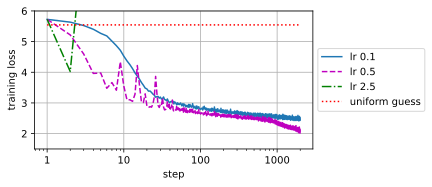

In [15]:
lm_sgd, _ = lr_sweep(make_lm, sgd, data, lrs=[0.1, 0.5, 2.5], seed=new_seed())
d2l.plot(list(range(1, 2001)),
         list(lm_sgd.values()) + [[math.log(256)] * 2000],
         'step', 'training loss', xscale='log', ylim=[1.5, 6],
         legend=[f'lr {lr:g}' for lr in lm_sgd] + ['uniform guess'],
         legend_loc='outside', figsize=(5, 2.5))

<!-- d2l:prose id=test-models-md-15 fw=all -->

* **Too high ($\eta = 2.5$):** Exceeds the local stability threshold $2/L$ after the first step and diverges to `inf` within ten steps.
* **Too low ($\eta = 0.1$):** Descends smoothly but slowly, reaching only $\sim 2.5$ nats/byte (bigram level) at step $2{,}000$.
* **Well-tuned ($\eta = 0.5$):** Experiences brief early transient spikes as the network navigates initial high-curvature regions, then recovers and reaches about $2.1$ nats/byte.

On `FashionCNN`, plain SGD at $\eta = 0.3$ reaches a training loss of $\sim 0.22$ and a held-out test accuracy of $\sim 90\%$:

In [16]:
test_acc = lambda model: evaluate_accuracy(model, fashion.val_dataloader())
cnn_sgd, _ = lr_sweep(FashionCNN, sgd, fashion, lrs=[0.3], seed=new_seed(),
                      evaluate=test_acc, metric='test accuracy')

lr 0.3: final loss 0.216, test accuracy 0.905


<!-- d2l:prose id=test-models-md-16 fw=all -->

### Comparison Protocol and Significance Thresholds

Following the Deep Learning Tuning Playbook [@Godbole.Dahl.Gilmer.ea.2023], comparing two optimizers fairly requires treating the learning rate $\eta$ as a **nuisance hyperparameter** that must be swept independently for each method (`lr_sweep` over a log-spaced grid from shared initial weights) rather than comparing two optimizers at an arbitrary shared learning rate [@Schmidt.Schneider.Hennig.2021]. Alongside the minimum loss achieved at each optimizer's best learning rate, we track its **usable learning-rate range** (grid points finishing within $0.15$ nats of the optimum).

Across $5$ independent random seeds at a well-tuned learning rate, the final $100$-step training loss (`final_loss`) and validation loss of `TinyLM` vary over a range of $\sim 0.01\text{--}0.015$ nats, while `FashionCNN` varies by $\sim 0.02$ in training loss and $\sim 1\%$ in test accuracy. Adopting a conservative $3\times$ range margin, we treat a single-run difference as statistically meaningful only if it exceeds **$0.05$ nats** on `TinyLM` or **$0.06$ training loss ($3\%$ test accuracy)** on `FashionCNN`; smaller differences are treated as ties unless confirmed across multiple seeds.

## Summary

* `TinyLM` ($470{,}784$ parameters: $90\%$ 2D projection matrices, $9\%$ embeddings, $<1\%$ 1D vectors) trains on random $64$-byte windows of WikiText-103 ($\sim 2.7 \times 10^8$ bytes), so a $2{,}000$-step run evaluates fresh text on every step.
* `FashionCNN` ($421{,}642$ parameters) trains on $256$-image minibatches of Fashion-MNIST ($\sim 8.5$ epochs in $2{,}000$ steps) and is evaluated by both training loss and held-out test accuracy.
* Every optimizer comparison sweeps the learning rate $\eta$ independently for each method from identical initial weights, reporting both the optimal loss and the usable learning-rate range against a multi-seed significance threshold of $0.05$ nats on `TinyLM`.

## Exercises

1. **Initial loss before training.**
    1. If logits $z_1, \ldots, z_V$ are drawn i.i.d. from $\mathcal{N}(0, s^2)$ independently of the target, use $\sum_{i=1}^V e^{z_i} \approx V \mathbb{E}[e^{z_i}] = V e^{s^2/2}$ to show that the expected initial cross-entropy is approximately $\ln V + s^2 / 2$.
    1. Given LayerNorm outputs of mean $0$ and variance $1$ and head weights/biases drawn from $\mathcal{U}(-1/\sqrt{128}, 1/\sqrt{128})$, show that $s^2 = 129/384 \approx 1/3$ and $\ln 256 + 1/6 \approx 5.71$ nats, matching the step-$1$ loss of `TinyLM`. What is the initial loss if the head weights and bias are initialized to zero?

1. [code] **Diagnosing loss curves on `FashionCNN`.** Train `FashionCNN` with plain SGD across $\eta \in \{0.003, 0.03, 0.3, 1.0\}$ and plot the step losses on a logarithmic step axis against the uniform baseline $\ln 10 \approx 2.3026$. For the run that stalls near $\ln 10$, inspect the fraction of dead ReLU activations across a minibatch to explain why gradients vanish.

1. [code] **The edge of divergence on `TinyLM`.** Sweep plain SGD on `TinyLM` across $\eta \in \{0.7, 1.0, 1.4, 2.0\}$ across $5$ seeds (`lr_sweep(..., verbose=False)`). Record the survival rate, the step at which divergent runs fail, and the lowest surviving loss.

1. [code] **Multi-seed spread and standard error.** ● Run $20$ seeds of `TinyLM` with AdamW (that section) at $\eta = 3 \times 10^{-3}$ (`weight_decay=0`), compare the sample standard deviation $\sigma$ of `final_loss` against the normal range estimator $\text{range}/3.7$, and compute how many seeds $k$ are required to detect a $0.005$-nat difference at two standard errors ($\sigma\sqrt{2/k}$).

1. [code] **Training loss vs. validation loss and overfitting small corpora.**
    1. Explain why `final_loss` (averaged over the last $100$ training steps) is slightly higher ($0.02\text{--}0.03$ nats) than the post-step-$2000$ validation loss on `TinyLM`, and verify by evaluating the final checkpoint on held-out training windows.
    1. Restrict the corpus to $100{,}000$ bytes via `WikiText103(batch_size=64, num_steps=64, num_train=100000)` ($\sim 80$ epochs in $2{,}000$ steps) and plot training vs. validation loss every $250$ steps (`every=250`).

1. [code] **Count-based $n$-gram landmarks.** Compute the empirical byte unigram entropy ($\sim 3.2$ nats) and add-one smoothed bigram ($\sim 2.5$ nats) and trigram cross-entropies from the first $10^7$ training bytes of `WikiText103` evaluated on the validation split, and compare them against the $2{,}000$-step SGD (about $2.1$ nats) and AdamW ($1.59$ nats, that section) losses of `TinyLM`.

[Discussions](https://d2l.discourse.group/t/36884)